# 04 · European car sales and costs

**Requirement 4 · 10 points · grouped horizontal bar chart**

Compare transaction totals for **United Kingdom, Germany, and France**. Horizontal bars accommodate the long country name, start at zero, and allow direct comparisons. A pie chart would obscure differences between sales and costs.

**Source:** `data/Simplified Car Sales Data.xlsx`, `CarSalesData` worksheet, 457 transactions overall; 259 belong to the three required countries.

**Definitions:** sales = `sum(SalePrice)`; total costs = `sum(CostPrice + LaborCost)`. Both cost components are provided and itemized below. If the module defines “costs” as purchase cost only, that would be a different measure: the notebook exposes it as `purchase_cost` rather than silently mixing definitions. The student confirmed **USD**; amounts are not converted. The source workbook itself has no currency label.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'config').is_dir() else Path.cwd().parent
assert (ROOT / 'config/assignment.json').is_file(), 'Open from the repository or notebooks directory.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from dv_assignment.data import config
from dv_assignment.data import course_sales
from dv_assignment import charts


## Aggregate transactions, not unit prices

There is no quantity field. Each row supplies sale, purchase, and labor amounts. Filter the assigned countries, validate nonmissing numeric values, and sum the transaction amounts. The three countries must all be present.

In [2]:
totals = course_sales(config()['sales'])
display(totals.style.format('{:,.0f}'))
assert (totals.total_costs == totals.purchase_cost + totals.labor_cost).all()
print(f"Selected transactions: {totals.transactions.sum():,}")

,total_sales,purchase_cost,labor_cost,total_costs,transactions
country,,,,,
United Kingdom,"15,725,000","10,193,880","129,952","10,323,832",215
France,"2,524,510","1,460,100","36,471","1,496,571",40
Germany,"145,750","160,000","1,461","161,461",4


Selected transactions: 259


## Required horizontal bar chart

Two adjacent horizontal bars per country show sales and total costs on one monetary axis. The ordering follows sales. Direct labels give totals in millions, and the table above retains exact amounts.

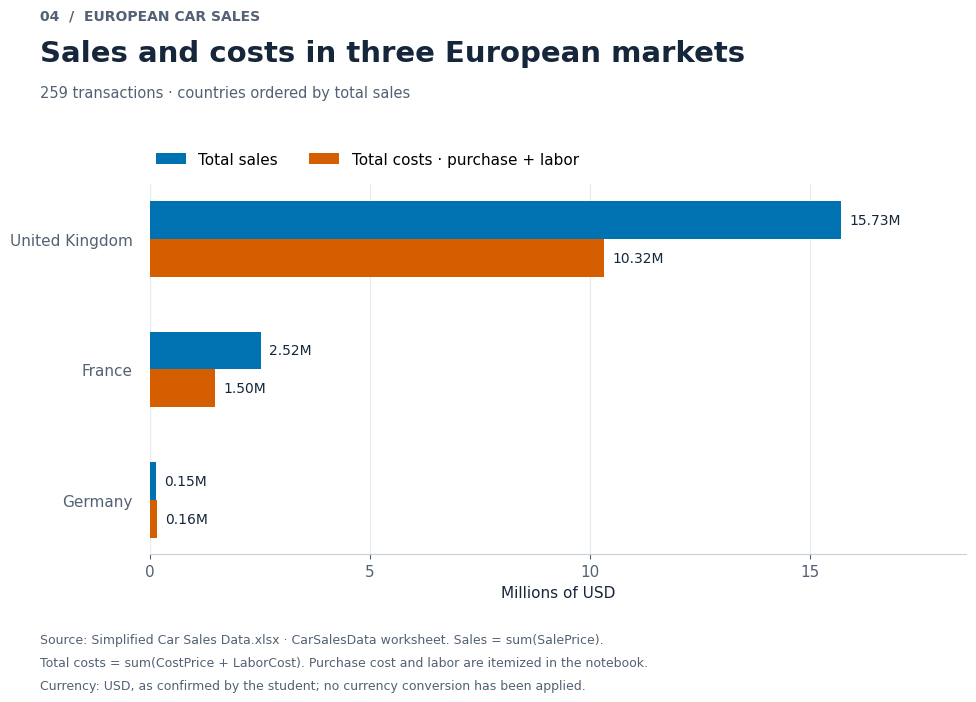

In [3]:
fig = charts.car_sales(totals)
charts.export(fig, ROOT / 'figures', '04_european_car_sales')
plt.show()

## Interpretation

The United Kingdom has the highest total sales and the most transactions in this subset. Germany's total costs exceed sales; that is retained rather than corrected away. This chart measures transaction volume and amounts, not profit margin per vehicle. Different transaction counts and vehicle mixes affect the comparison.